In [1]:
import pandas as pd
import numpy as np

# Step 1: CSV file loaded
df = pd.read_csv("supermarket_sales_case_study.csv")


# Step 1: kitni rows aur kitne columns hain
print(df.shape)

# Step 1: pehli 5 rows dekho
df.head()

(8631, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,1/1/2023,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,1/1/2023,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,1/1/2023,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,1/1/2023,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,1/1/2023,17:36,Cash,171.88,4.761905,8.5940,5.3


In [2]:
# Step 1: har column ki type (dtype) aur non-null count dekho
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8631 entries, 0 to 8630
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               8631 non-null   object 
 1   Branch                   8631 non-null   object 
 2   City                     8631 non-null   object 
 3   Customer type            8567 non-null   object 
 4   Gender                   8631 non-null   object 
 5   Product line             8631 non-null   object 
 6   Unit price               8631 non-null   float64
 7   Quantity                 8631 non-null   int64  
 8   Tax 5%                   8631 non-null   float64
 9   Total                    8631 non-null   float64
 10  Date                     8614 non-null   object 
 11  Time                     8631 non-null   object 
 12  Payment                  8631 non-null   object 
 13  cogs                     8631 non-null   float64
 14  gross margin percentage 

In [3]:
# Step 10: audit trail ek khaali list se shuru kartay hai
audit_trail = []

# Step 1 chhota function -- har step ke baad rows ka hisaab save karein gay
def log_step(step_name):
    rows_now = len(df)                                   # abhi kitni rows hain
    if len(audit_trail) == 0:
        removed = 0                                      # pehle step mein kuch remove nahi hua
    else:
        removed = audit_trail[-1]["rows"] - rows_now     # pichle step ke muqable mein kitni kam hui
    audit_trail.append({"step": step_name, "rows": rows_now, "removed": removed})


# Step 1: pehli entry -- raw file load hui
log_step("1. raw file loaded")
rows_in = len(df)
print("rows loaded:", rows_in)

rows loaded: 8631


In [4]:

# Step 2: har column mein missing values (count aur percent)
audit = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
print(audit)




# Step 2: exact duplicate rows (har column bilkul same)
print("exact duplicate rows:", df.duplicated().sum())


# Step 2: wo rows jin ka Invoice ID kisi aur row se share hota hai (keep=False = sab copies gino)
print("rows sharing an Invoice ID:", df.duplicated(subset="Invoice ID", keep=False).sum())


# Step 2: kitne Invoice IDs aise hain jo ek se zyada baar aaye
print("Invoice IDs that repeat:", df["Invoice ID"].value_counts().gt(1).sum())


# Step 2: Gender aur Payment ki distinct values (NaN bhi dikhao)
print(df["Gender"].value_counts(dropna=False))
print()
print(df["Payment"].value_counts(dropna=False))

                         missing_count  missing_percent
Invoice ID                           0             0.00
Branch                               0             0.00
City                                 0             0.00
Customer type                       64             0.74
Gender                               0             0.00
Product line                         0             0.00
Unit price                           0             0.00
Quantity                             0             0.00
Tax 5%                               0             0.00
Total                                0             0.00
Date                                17             0.20
Time                                 0             0.00
Payment                              0             0.00
cogs                                 0             0.00
gross margin percentage              0             0.00
gross income                         0             0.00
Rating                              88          

In [5]:
# Step 3: pehle count
print("Before exact duplicate rows:", df.duplicated().sum())

# Step 3: exact duplicates drop karo (pehli copy rakhi jati hai)
df = df.drop_duplicates()

# Step 3: baad mein count (0 hona chahiye)
print("After exact duplicate rows:", df.duplicated().sum())

log_step("3. exact duplicates dropped")

Before exact duplicate rows: 30
After exact duplicate rows: 0


In [6]:

# Step 4: RULE -- agar ek Invoice ID do baar aaye to LATER wali row correction hai,
# is liye hamesha AAKHRI (last) row rakho aur purani row hata do.
print("conflicting Invoice ID rows (jo hatengi):", df["Invoice ID"].duplicated(keep="last").sum())

df = df.drop_duplicates(subset="Invoice ID", keep="last")

# Step 4: ab har Invoice ID sirf ek baar hona chahiye (0 aana chahiye)
print("repeated Invoice IDs now:", df["Invoice ID"].duplicated().sum())

log_step("4. conflicting Invoice IDs resolved (keep last)")

conflicting Invoice ID rows (jo hatengi): 25
repeated Invoice IDs now: 0


In [7]:
# Step 5: extra spaces hatao aur lowercase karo (strip = shuru/aakhir ke space, replace = beech ke zyada spaces)
for col in ["Gender", "Payment"]:
    df[col] = df[col].str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

# Step 5: har ghalat spelling ko ek sahi naam par map karne ki dictionary
# (Step 2 mein jo distinct values nazar aayin, agar koi nayi ho to yahan add kar do)
gender_map = {
    "male": "Male", "m": "Male", "mal": "Male",
    "female": "Female", "f": "Female", "femal": "Female", "femle": "Female",
}
payment_map = {
    "cash": "Cash",
    "credit card": "Credit card", "creditcard": "Credit card", "credit": "Credit card",
    "ewallet": "Ewallet", "e-wallet": "Ewallet", "e wallet": "Ewallet",
}

df["Gender"] = df["Gender"].map(gender_map)
df["Payment"] = df["Payment"].map(payment_map)

# Step 5: check -- koi value map hone se reh to nahi gayi? (NaN = map nahi hui)
print(df["Gender"].value_counts(dropna=False))
print()
print(df["Payment"].value_counts(dropna=False))

log_step("5. text columns standardised")

Gender
Female    4539
Male      4037
Name: count, dtype: int64

Payment
Ewallet        3215
Cash           2796
Credit card    2565
Name: count, dtype: int64


In [8]:
# Step 6: Quantity ko number banao (agar text ho to NaN ban jaye)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

# Step 6: kitni negative quantities hain
print("negative quantities before:", (df["Quantity"] < 0).sum())

# Step 6: absolute value lo (minus hat jata hai)
df["Quantity"] = df["Quantity"].abs()

print("negative quantities after:", (df["Quantity"] < 0).sum())

log_step("6. negative quantities fixed")

negative quantities before: 57
negative quantities after: 0


In [9]:
# Step 7: Date column ko text banao aur extra spaces remove katay hai
date_text = df["Date"].astype(str).str.strip()

# Step 7: pehla format : month/day/year (jaise 1/6/2023)
date_first = pd.to_datetime(date_text, format="%m/%d/%Y", errors="coerce")

# Step 7: doosra format day-month-year (jaise 06-01-2023)
date_second = pd.to_datetime(date_text, format="%d-%m-%Y", errors="coerce")

# Step 7: jahan pehla fail (NaT) hua wahan doosra use karo; dono fail = missing rahegi
df["Date"] = date_first.fillna(date_second)

print("dates parsed:", df["Date"].notna().sum())
print("dates missing (NaT):", df["Date"].isna().sum())

log_step("7. mixed dates parsed")

dates parsed: 8514
dates missing (NaT): 62


In [10]:
# Step 8: Unit price aur Total ko number banatay hai
df["Unit price"] = pd.to_numeric(df["Unit price"], errors="coerce")
df["Total"] = pd.to_numeric(df["Total"], errors="coerce")

# Step 8: formula wala Total = Quantity x Unit price x 1.05
total_formula = df["Quantity"] * df["Unit price"] * 1.05

# Step 8: file ke Total aur formula ke Total mein farq (positive number mein)
difference = (df["Total"] - total_formula).abs()

# Step 8: ghalat rows = farq 0.50 se zyada, ya Total khaali hai (aur formula nikal sakta hai)
wrong_total = (difference > 0.50) | (df["Total"].isna() & total_formula.notna())
print("rows jinka Total ghalat tha:", wrong_total.sum())

# Step 8: ghalat rows mein formula ki value (2 decimal) laga daytay hai
df.loc[wrong_total, "Total"] = total_formula[wrong_total].round(2)

log_step("8. Total checked and corrected")

rows jinka Total ghalat tha: 62


In [11]:

# Step 9: Customer type ki missing values ko "Unknown" se bhatay hain
df["Customer type"] = df["Customer type"].fillna("Unknown")

# Step 9: Rating number banatay hai , phir median nikaltay hai  aur missing ko usse bhatay hain
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
median_rating = df["Rating"].median()
df["Rating"] = df["Rating"].fillna(median_rating)
print("median rating:", median_rating)

# Step 9: jin rows ki Date missing hai unhein drop kartay hai
rows_before_drop = len(df)
df = df[df["Date"].notna()].copy()
print("rows with no date dropped:", rows_before_drop - len(df))

log_step("9. missing values handled, no-date rows dropped")

median rating: 7.1
rows with no date dropped: 62


In [12]:
# Step 10: audit trail list ko table (DataFrame) bana kar dikhtay hai
audit_trail_df = pd.DataFrame(audit_trail)
print(audit_trail_df)
print()
print("total rows removed:", audit_trail_df["removed"].sum())
print("final clean rows:", len(df))


# Step 10: check -- clean data mein ab koi missing nahi hona chahiye (Date, Quantity, Total, Rating)
print(df[["Date", "Quantity", "Unit price", "Total", "Rating", "Customer type"]].isnull().sum())
df.head()

                                              step  rows  removed
0                               1. raw file loaded  8631        0
1                      3. exact duplicates dropped  8601       30
2  4. conflicting Invoice IDs resolved (keep last)  8576       25
3                     5. text columns standardised  8576        0
4                     6. negative quantities fixed  8576        0
5                            7. mixed dates parsed  8576        0
6                   8. Total checked and corrected  8576        0
7  9. missing values handled, no-date rows dropped  8514       62

total rows removed: 117
final clean rows: 8514
Date             0
Quantity         0
Unit price       0
Total            0
Rating           0
Customer type    0
dtype: int64


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,2023-01-01,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,2023-01-01,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,2023-01-01,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,2023-01-01,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,2023-01-01,17:36,Cash,171.88,4.761905,8.5940,5.3


In [13]:

# Brief 1: Year -- Date se saal nikalo
df["Year"] = df["Date"].dt.year


# Brief 1: Quarter -- jaise 2023Q1 (to_period("Q") quarter banata hai, astype(str) text mein badalta hai)
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)


# Brief 1: Day of week -- din ka naam (Monday, Tuesday, ...)
df["Day of week"] = df["Date"].dt.day_name()


# Brief 1: Hour -- Time column se ghanta nikalo (pehle "13:08" format, phir "13:08:45" try karo)
time_text = df["Time"].astype(str).str.strip()
time_first = pd.to_datetime(time_text, format="%H:%M", errors="coerce")
time_second = pd.to_datetime(time_text, format="%H:%M:%S", errors="coerce")
df["Hour"] = time_first.fillna(time_second).dt.hour.astype("Int64")


print("missing Hour:", df["Hour"].isna().sum())
df[["Date", "Time", "Year", "Quarter", "Day of week", "Hour"]].head()

missing Hour: 0


,Date,Time,Year,Quarter,Day of week,Hour
0,2023-01-01,12:46,2023,2023Q1,Sunday,12
1,2023-01-01,17:55,2023,2023Q1,Sunday,17
2,2023-01-01,12:40,2023,2023Q1,Sunday,12
3,2023-01-01,17:20,2023,2023Q1,Sunday,17
4,2023-01-01,17:36,2023,2023Q1,Sunday,17


In [14]:
# Brief 2: np.select se Hour ko bucket mein badaltay hai  (if / elif / elif ki tarah)
conditions = [
    (df["Hour"] >= 10) & (df["Hour"] < 13),   # Morning
    (df["Hour"] >= 13) & (df["Hour"] < 17),   # Afternoon
    (df["Hour"] >= 17) & (df["Hour"] < 21),   # Evening
]
choices = ["Morning", "Afternoon", "Evening"]
df["Time bucket"] = np.select(conditions, choices, default="Outside hours")

print(df["Time bucket"].value_counts())

Time bucket
Evening      3409
Afternoon    2953
Morning      2152
Name: count, dtype: int64


In [15]:
# Brief 2: har bucket mein kitne hour hain (dictionary)
hours_in_bucket = {"Morning": 3, "Afternoon": 4, "Evening": 4}

# Brief 2: har bucket ke transactions gintay hai  aur sahi order mein lagatay hai
bucket_table = df["Time bucket"].value_counts().reindex(["Morning", "Afternoon", "Evening"]).to_frame("Transactions")

# Brief 2: hour add kartay hai aur formula lagtay hai: transactions / hours
bucket_table["Hours"] = bucket_table.index.map(hours_in_bucket)
bucket_table["Transactions per hour"] = (bucket_table["Transactions"] / bucket_table["Hours"]).round(2)
bucket_table

,Transactions,Hours,Transactions per hour
Time bucket,,,
Morning,2152,3,717.33
Afternoon,2953,4,738.25
Evening,3409,4,852.25


In [16]:
# Brief 3: har branch aur har quarter ki revenue (Total ka sum)
quarterly = df.groupby(["Branch", "Quarter"])["Total"].sum().reset_index()
quarterly = quarterly.rename(columns={"Total": "Revenue"})
quarterly.head()


# Brief 3: chhota targets table -- har branch ka target $100,000
branches = sorted(df["Branch"].unique())
targets = pd.DataFrame({"Branch": branches, "Target": 100000})
print(targets)

# Brief 3: revenue table ko targets table se join (merge) kartay hai
quarterly = quarterly.merge(targets, on="Branch", how="left")

# Brief 3: formulas -- Variance, % of target, Hit
quarterly["Variance"] = quarterly["Revenue"] - quarterly["Target"]
quarterly["% of target"] = (quarterly["Revenue"] / quarterly["Target"] * 100).round(2)
quarterly["Hit"] = quarterly["Revenue"] >= quarterly["Target"]

quarterly["Revenue"] = quarterly["Revenue"].round(2)
quarterly["Variance"] = quarterly["Variance"].round(2)
quarterly

  Branch  Target
0      A  100000
1      B  100000
2      C  100000


,Branch,Quarter,Revenue,Target,Variance,% of target,Hit
0,A,2023Q1,102248.79,100000,2248.79,102.25,True
1,A,2023Q2,90064.16,100000,-9935.84,90.06,False
2,A,2023Q3,90878.34,100000,-9121.66,90.88,False
3,A,2023Q4,129821.33,100000,29821.33,129.82,True
4,A,2024Q1,112450.64,100000,12450.64,112.45,True
5,A,2024Q2,98243.28,100000,-1756.72,98.24,False
6,A,2024Q3,89175.67,100000,-10824.33,89.18,False
7,A,2024Q4,117506.81,100000,17506.81,117.51,True
8,B,2023Q1,96366.00,100000,-3634.00,96.37,False
9,B,2023Q2,91993.33,100000,-8006.67,91.99,False


In [17]:

# Brief 4: har branch ki saal-ba-saal revenue (rows = Branch, columns = Year)
year_revenue = df.groupby(["Branch", "Year"])["Total"].sum().unstack()

# Brief 4: YoY growth % = (2024 / 2023 - 1) x 100
yoy_growth = ((year_revenue[2024] / year_revenue[2023] - 1) * 100).round(2)

# Brief 4: har branch ke liye loop chalatay hai  aur summary ki row banatay hai
summary_rows = []
for branch in branches:
    one = quarterly[quarterly["Branch"] == branch]                 # sirf is branch ki quarters
    best_q = one.loc[one["Revenue"].idxmax(), "Quarter"]           # sab se zyada revenue wali quarter
    worst_q = one.loc[one["Revenue"].idxmin(), "Quarter"]          # sab se kam revenue wali quarter
    summary_rows.append({
        "Branch": branch,
        "Avg quarterly revenue": round(one["Revenue"].mean(), 2),
        "Quarters hit (of 8)": int(one["Hit"].sum()),
        "Best quarter": best_q,
        "Worst quarter": worst_q,
        "YoY growth %": yoy_growth[branch],
    })

branch_summary = pd.DataFrame(summary_rows)
branch_summary

,Branch,Avg quarterly revenue,Quarters hit (of 8),Best quarter,Worst quarter,YoY growth %
0,A,103798.63,4,2023Q4,2024Q3,1.06
1,B,93167.82,2,2024Q4,2024Q2,-5.26
2,C,103296.89,4,2024Q4,2023Q2,8.40


Monday        9.19
Tuesday       9.71
Wednesday    10.20
Thursday     10.29
Friday       12.59
Saturday     15.42
Sunday       14.14
Name: count, dtype: float64


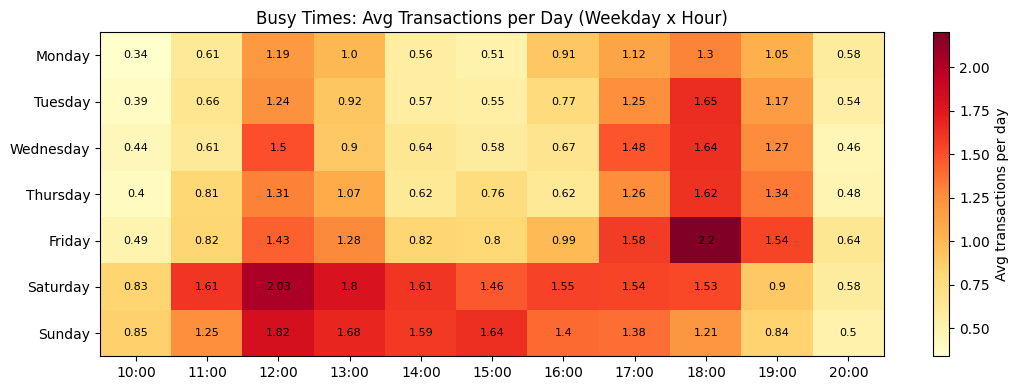

In [18]:
# Brief 5: data ki pehli se aakhri date tak saare din banao, aur gino har weekday kitni baar aaya
all_days = pd.date_range(df["Date"].min(), df["Date"].max())
weekday_counts = pd.Series(all_days.day_name()).value_counts()


# Brief 5: weekdays ka sahi order
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


# Brief 5: har weekday par kul transactions
transactions_weekday = df["Day of week"].value_counts()


# Brief 5: average per day = transactions / us weekday ki kul tadad
avg_per_day = (transactions_weekday / weekday_counts).reindex(weekday_order).round(2)
print(avg_per_day)


# Brief 5: weekday x hour table -- har cell mein transactions ki count
hour_counts = pd.crosstab(df["Day of week"], df["Hour"])

# Brief 5: har row ko us weekday ki tadad se divide karo (average per day)
hour_avg = hour_counts.div(weekday_counts, axis=0).reindex(weekday_order).round(2)
hour_avg




# Brief 5: heatmap (matplotlib se -- sirf plotting ke liye)
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))
plt.imshow(hour_avg.values, cmap="YlOrRd", aspect="auto")        # rang = busy level
plt.colorbar(label="Avg transactions per day")
plt.xticks(range(len(hour_avg.columns)), [f"{int(h)}:00" for h in hour_avg.columns])   # x axis = hours
plt.yticks(range(len(hour_avg.index)), hour_avg.index)                                  # y axis = weekdays

# har cell ke andar number likho
for i in range(hour_avg.shape[0]):
    for j in range(hour_avg.shape[1]):
        plt.text(j, i, hour_avg.values[i, j], ha="center", va="center", fontsize=8)

plt.title("Busy Times: Avg Transactions per Day (Weekday x Hour)")
plt.tight_layout()
plt.show()

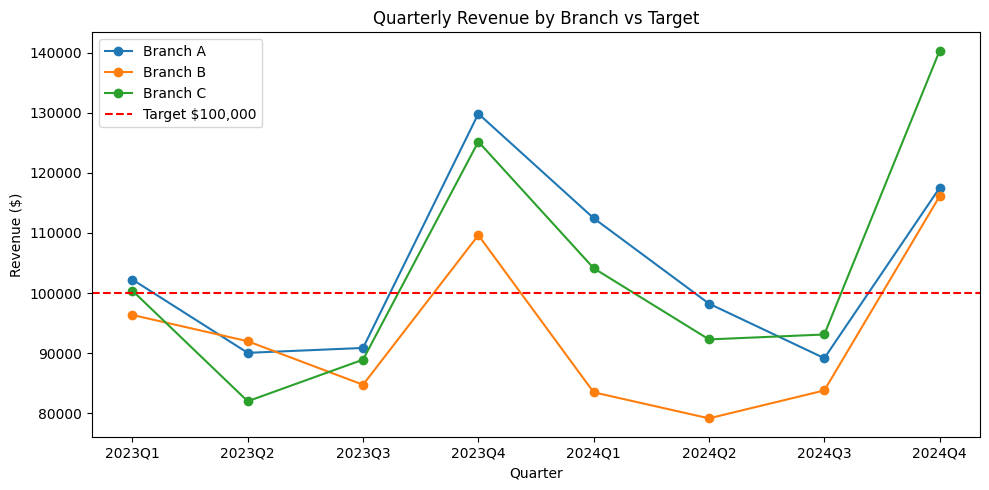

wrote 8,514 clean rows to supermarket_clean.csv
1) Data: 8,631 raw rows cleaned to 8,514 rows; total revenue $2,402,106.66.
2) Top branch by revenue: Branch A ($830,389.03).
3) Targets: 10 of 24 branch-quarters reached $100,000.
4) Fastest growth 2023 to 2024: Branch C (8.40% YoY).
5) Busiest: Saturday (15.42 transactions/day) and Evening (852.25 per hour).


In [19]:
# Brief 6: chart ke liye table -- rows = Quarter, columns = Branch
chart_data = quarterly.pivot(index="Quarter", columns="Branch", values="Revenue")

plt.figure(figsize=(10, 5))
for branch in chart_data.columns:
    plt.plot(chart_data.index, chart_data[branch], marker="o", label=f"Branch {branch}")   # har branch ki line

plt.axhline(100000, color="red", linestyle="--", label="Target $100,000")                  # target ki line
plt.title("Quarterly Revenue by Branch vs Target")
plt.xlabel("Quarter")
plt.ylabel("Revenue ($)")
plt.legend()
plt.tight_layout()
plt.show()





# Brief 6: clean data CSV mein save karo
df.to_csv("supermarket_clean.csv", index=False)


# Brief 6: audit trail aur branch summary bhi save kar lo (extra)
audit_trail_df.to_csv("supermarket_audit_trail.csv", index=False)
branch_summary.to_csv("supermarket_branch_summary.csv", index=False)

print(f"wrote {len(df):,} clean rows to supermarket_clean.csv")


# Brief 6: 5 line ka summary -- sab numbers data se khud nikalte hain
branch_revenue = df.groupby("Branch")["Total"].sum()
top_branch = branch_revenue.idxmax()
hits_total = int(quarterly["Hit"].sum())
best_yoy_branch = yoy_growth.idxmax()
busiest_day = avg_per_day.idxmax()
busiest_bucket = bucket_table["Transactions per hour"].idxmax()

print(f"1) Data: {rows_in:,} raw rows cleaned to {len(df):,} rows; total revenue ${df['Total'].sum():,.2f}.")
print(f"2) Top branch by revenue: Branch {top_branch} (${branch_revenue[top_branch]:,.2f}).")
print(f"3) Targets: {hits_total} of {len(quarterly)} branch-quarters reached $100,000.")
print(f"4) Fastest growth 2023 to 2024: Branch {best_yoy_branch} ({yoy_growth[best_yoy_branch]:.2f}% YoY).")
print(f"5) Busiest: {busiest_day} ({avg_per_day[busiest_day]} transactions/day) and {busiest_bucket} ({bucket_table.loc[busiest_bucket, 'Transactions per hour']} per hour).")